<a href="https://colab.research.google.com/github/anishkumarcs24/BIS/blob/main/Enhancing_Image_Processing_Efficiency.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
pip install opencv-python numpy matplotlib

Saving rome-cityscape-starry-night-desktop-wallpaper-cover.jpg to rome-cityscape-starry-night-desktop-wallpaper-cover.jpg
Image uploaded successfully!
Image dimensions: 768 x 432

===== RESULTS =====
CPU Cores: 2
Sequential Time: 0.0277 seconds
Parallel Time: 0.0402 seconds
Speedup: 0.69 x
CPU Efficiency: 34.44 %
Results Match: False


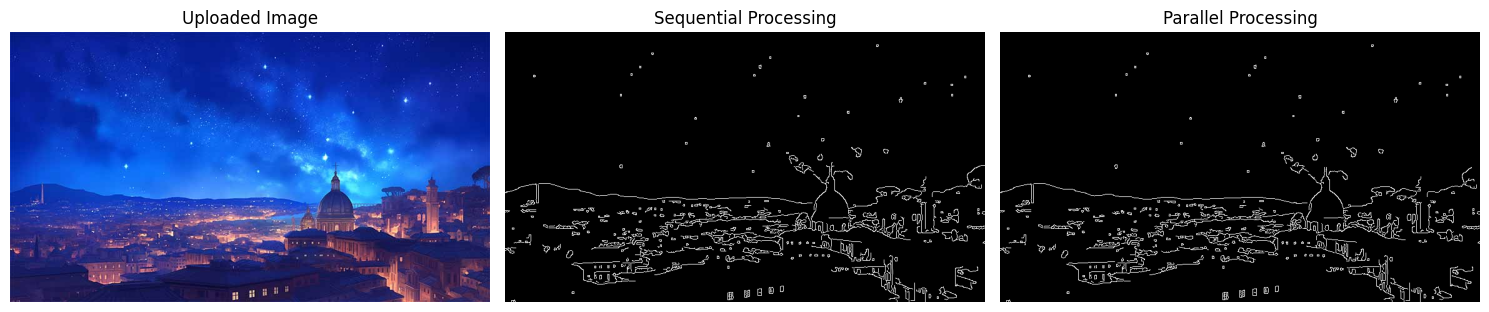

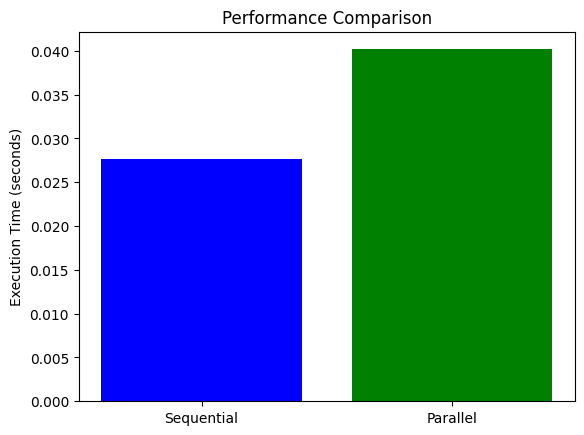

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import multiprocessing as mp
from google.colab import files
from concurrent.futures import ProcessPoolExecutor

# =================================
# 1. UPLOAD IMAGE
# =================================

uploaded = files.upload()

filename = next(iter(uploaded))

image_array = np.frombuffer(
    uploaded[filename], dtype=np.uint8
)

image = cv2.imdecode(
    image_array, cv2.IMREAD_COLOR
)

if image is None:
    raise ValueError("Unable to read uploaded image")

height, width = image.shape[:2]

print("Image uploaded successfully!")
print("Image dimensions:", width, "x", height)


# =================================
# 2. IMAGE PROCESSING
# =================================

def process_image(img):

    gray = cv2.cvtColor(
        img, cv2.COLOR_BGR2GRAY
    )

    blur = cv2.GaussianBlur(
        gray, (5, 5), 0
    )

    edges = cv2.Canny(
        blur, 50, 150
    )

    return edges


# =================================
# 3. SEQUENTIAL PROCESSING
# =================================

start = time.perf_counter()

sequential_result = process_image(image)

sequential_time = time.perf_counter() - start


# =================================
# 4. PARALLEL PROCESSING
# =================================

def worker(part):

    return process_image(part)


if __name__ == "__main__":

    num_cores = min(mp.cpu_count(), 4, height)

    # Divide image into sections
    chunks = np.array_split(
        image, num_cores, axis=0
    )

    start = time.perf_counter()

    with ProcessPoolExecutor(
        max_workers=num_cores
    ) as executor:

        results = list(
            executor.map(worker, chunks)
        )

    parallel_result = np.vstack(results)

    parallel_time = time.perf_counter() - start


    # =================================
    # 5. PERFORMANCE COMPARISON
    # =================================

    speedup = sequential_time / parallel_time

    efficiency = (speedup / num_cores) * 100

    print("\n===== RESULTS =====")

    print("CPU Cores:", num_cores)

    print("Sequential Time:",
          round(sequential_time, 4), "seconds")

    print("Parallel Time:",
          round(parallel_time, 4), "seconds")

    print("Speedup:",
          round(speedup, 2), "x")

    print("CPU Efficiency:",
          round(efficiency, 2), "%")

    print("Results Match:",
          np.array_equal(
              sequential_result,
              parallel_result
          ))


    # =================================
    # 6. DISPLAY IMAGES
    # =================================

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    )
    plt.title("Uploaded Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(sequential_result, cmap="gray")
    plt.title("Sequential Processing")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(parallel_result, cmap="gray")
    plt.title("Parallel Processing")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


    # =================================
    # 7. EXECUTION TIME GRAPH
    # =================================

    plt.bar(
        ["Sequential", "Parallel"],
        [sequential_time, parallel_time],
        color=["blue", "green"]
    )

    plt.ylabel("Execution Time (seconds)")
    plt.title("Performance Comparison")
    plt.show()
